In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

%matplotlib inline

url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-SkillsNetwork/labs/Data%20files/automobileEDA.csv"
df = pd.read_csv(url)

df.head()

,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1


In [2]:
correlation_matrix = df[['bore', 'stroke', 'compression-ratio', 'horsepower']].corr()
correlation_matrix

,bore,stroke,compression-ratio,horsepower
bore,1.000000,-0.055390,0.001263,0.566936
stroke,-0.055390,1.000000,0.187923,0.098462
compression-ratio,0.001263,0.187923,1.000000,-0.214514
horsepower,0.566936,0.098462,-0.214514,1.000000


Матриця кореляції:
          stroke    price
stroke  1.00000  0.08231
price   0.08231  1.00000


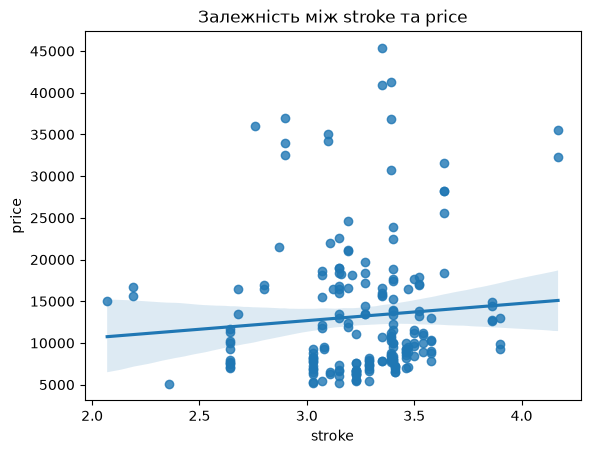

In [3]:
stroke_price_corr = df[['stroke', 'price']].corr()
print("Матриця кореляції:\n", stroke_price_corr)

sns.regplot(x="stroke", y="price", data=df)
plt.title("Залежність між stroke та price")
plt.show()

In [4]:
df_group_body = df[['body-style', 'price']].groupby(['body-style'], as_index=False).mean()
df_group_body.rename(columns={'price': 'average_price'}, inplace=True)
df_group_body

/tmp/ipykernel_1123487/3464487939.py:2: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_group_body.rename(columns={'price': 'average_price'}, inplace=True)


,body-style,average_price
0,convertible,21890.500000
1,hardtop,22208.500000
2,hatchback,9957.441176
3,sedan,14459.755319
4,wagon,12371.960000


In [5]:
pearson_coef, p_value = stats.pearsonr(df['wheel-base'], df['price'])
print(f"Коефіцієнт кореляції Пірсона: {pearson_coef}")
print(f"P-value: {p_value}")

Коефіцієнт кореляції Пірсона: 0.584641822265508
P-value: 8.076488270732947e-20


In [6]:
pearson_coef_hp, p_value_hp = stats.pearsonr(df['horsepower'], df['price'])
print(f"Коефіцієнт кореляції Пірсона: {pearson_coef_hp}")
print(f"P-value: {p_value_hp}")

Коефіцієнт кореляції Пірсона: 0.8095745670036562
P-value: 6.369057428259571e-48


In [ ]:
grouped_test_drive = df[['drive-wheels', 'price']].groupby('drive-wheels')

f_val_drive, p_val_drive = stats.f_oneway(
    grouped_test_drive.get_group('fwd')['price'], 
    grouped_test_drive.get_group('rwd')['price'], 
    grouped_test_drive.get_group('4wd')['price']
)
print("ANOVA результати для 'drive-wheels' та 'price':")
print(f"F-test оцінка: {f_val_drive}")
print(f"P-value: {p_val_drive}\n")

grouped_test_body = df[['body-style', 'price']].groupby('body-style')

f_val_body, p_val_body = stats.f_oneway(
    grouped_test_body.get_group('hardtop')['price'],
    grouped_test_body.get_group('hatchback')['price'],
    grouped_test_body.get_group('sedan')['price'],
    grouped_test_body.get_group('wagon')['price'],
    grouped_test_body.get_group('convertible')['price']
)
print("ANOVA результати для 'body-style' та 'price':")
print(f"F-test оцінка: {f_val_body}")
print(f"P-value: {p_val_body}")

ANOVA результати для 'drive-wheels' та 'price':
F-test оцінка: 67.954065007804
P-value: 3.394544357715072e-23

ANOVA результати для 'body-style' та 'price':
F-test оцінка: 9.128751854708211
P-value: 8.779795237614596e-07
